<center>

## ARHITEKTURE NEURONSKIH MREŽA
## Vježba 6 <br> **Konvolucijske neruonske mreže**
<br>



</center>


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

### Skup podataka

> koristit ćemo **MNIST** skup podataka

<img src="https://miro.medium.com/v2/resize:fit:1200/1*v6Nn_zj8W0qsnk9Cc6Di_g.png" width=40%>


In [2]:
# Učitavanja podataka
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# Konvolucijske neuronske mreže

> Arhitektura neuronskih mreža prikaldna za rad s podacima koji imaju formu višedimenzionalnih nizova (**slike**).

Pokazala se iznimno uspješnom na različitim zadacima iz područja ***računalnog vida.***


## Slojevi konvolucijske mreže

### 1. **Konvolucijski slojevi**

Osnova je operacija **konvolucije**:


> Konvolucija 5x5 ulaza  $\begin{bmatrix} 3 & 3 & 2 & 1 & 0 \\ 0 & 0 & 1 & 3 & 1 \\  3 & 1 & 2 & 2 & 3 \\  2 & 0 & 0 & 2 & 2 \\ 2 & 0 &0 & 0&1 \end{bmatrix}$ i 3x3 filtera $\begin{bmatrix}
  0 & 1 & 2 \\
  2 & 2 & 0 \\
  0 & 1 & 2
  \end{bmatrix}$: <br> <br>
> <img alt='konvolucija.png' src='https://miro.medium.com/max/535/1*Zx-ZMLKab7VOCQTxdZ1OAw.gif' width='50%'> <br><br>
 > - rezultat konvolucije = **mapa značajki** (engl. *feature map*) tj. **aktivacijska mapa**
  




- Različiti filteri detektiraju različite značajke na slici.
- Vrijednosti (**težine**) filtera se uče za vrijeme treniranja mreže.
- Neuroni povezani samo **s dijelom ulaza**.
- Neuroni **dijele težine** $\implies$ reducira se broj parametara koji se uče.

[**Konvolucijski sloj** u `tf.keras`-u](](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D)) prima kao parametar *broj filtera*, *dimenzije filtera* i *korak* (engl. *stride*):

<br>

<img src='https://drive.google.com/uc?id=1oQbRv7tu-pYejDxRRrqMain-N_QLdQFA' width=40%>


### 2. **Pooling slojevi** (slojevi sažimanja)

-  reduciraju visinu i širinu ulaza
-  implementiraju invarijantnost na male translacije ulaza




<img alt='pool.png' src='https://www.researchgate.net/profile/Alla_Eddine_Guissous/publication/337336341/figure/fig15/AS:855841334898691@1581059883782/Example-for-the-max-pooling-and-the-average-pooling-with-a-filter-size-of-22-and-a.jpg' width='80%'>


> `tf.keras` dokumentacija:
- [*Max-Pooling*](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MaxPooling2D) sloj
- [*Average-pooling*](https://www.tensorflow.org/api_docs/python/tf/keras/layers/AveragePooling2D) sloj

### 3. **Potpuno povezani slojevi**

> najčešće na kraju mreže

## Priprema podataka

Za početak, pripremimo podatke za treniranje neuronske mreže.

> Podaci iz skupa za treniranje pohranjeni su u array oblika $(60000, 28, 28)$ i tipa `uint8` s vrijednostima u $[0,255]$.
>- Podatke transformiramo u `flaot32` array oblika $(60000, 28, 28, 1)$ s vrijednostima u $[0,1]$.

In [3]:
X_train = X_train.reshape((60000, 28, 28, 1))
X_train = X_train.astype('float32') / 255.

Analgno napravimo i sa skupom za testiranje

In [4]:
X_test = X_test.reshape((10000, 28, 28, 1))
X_test = X_test.astype('float32') / 255.

# Napravimo svoju prvu konvolucijsku mrežu

<img src='https://drive.google.com/uc?id=1jQFP8HTOVwiG49FQwcAoxxCXq6K47cAq' width = '60%'>

**Prvom** (*ulaznom*) **konvolucijskom sloju** šaljemo parametar `input_shape = (img_height, img_width, img_channels)`.



In [ ]:
model = tf.keras.models.Sequential()

model.add(tf.keras.Input(shape=(28, 28, 1)))
model.add(tf.keras.layers.Conv2D(32, kernel_size=(5, 5), activation='relu'))                # kernel_size - dimenzije filtera, po defaultu strides=(1,1)
model.add(tf.keras.layers.MaxPool2D(pool_size=(2, 2)))                                      # pool_size - dimenzija pooling okvira, po defaultu strides=pool_size
model.add(tf.keras.layers.Conv2D(64, kernel_size=(5, 5), activation='relu'))
model.add(tf.keras.layers.MaxPool2D(pool_size=(2, 2)))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(16, activation = 'relu'))
model.add(tf.keras.layers.Dense(10, activation ='softmax'))                                  # višeklasna klasifikacija s 10 mogućih klasa

model.compile(
    loss='sparse_categorical_crossentropy',                                                 # koristimo sparse_categorical_crossentropy funkciju gubitka koja NE trazi one-hot labele
    optimizer='adam',
    metrics=['accuracy']
)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        16,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,666 (268.23 KB)

 Trainable params: 68,666 (268.23 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print(f"Postoji {5*5*32+32} parametara za učenje u prvom sloju")

Postoji 832 parametara za učenje u prvom sloju


In [ ]:
povijest = model.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.2)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7672 - loss: 0.7011 - val_accuracy: 0.9738 - val_loss: 0.0893
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9739 - loss: 0.0874 - val_accuracy: 0.9735 - val_loss: 0.0877
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9827 - loss: 0.0572 - val_accuracy: 0.9842 - val_loss: 0.0549
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9883 - loss: 0.0366 - val_accuracy: 0.9867 - val_loss: 0.0472
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9907 - loss: 0.0293 - val_accuracy: 0.9868 - val_loss: 0.0446
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9923 - loss: 0.0226 - val_accuracy: 0.9879 - val_loss: 0.0444
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9934 - loss: 0.0206 - val_accuracy: 0.9891 - val_loss: 0.0402
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9940 - loss: 0.0159 - val_accuracy: 0.

In [ ]:
_, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("Tocnost na skupu za testiranje: {:.2f}%".format(test_acc*100))

Tocnost na skupu za testiranje: 99.13%


In [ ]:
br_pogresnih = int((1-test_acc)*X_test.shape[0])
print('Pogrešno razvrstanih slika: {}/{}'.format(br_pogresnih, X_test.shape[0]))

Pogrešno razvrstanih slika: 87/10000


In [ ]:
y_hat = model.predict(X_test)                                 # predviđanja modela na skupu za testiranje

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
y_hat[0]

array([1.7546580e-17, 5.4190707e-11, 3.0682041e-14, 2.1326469e-12,
       4.7727367e-22, 1.8771299e-18, 7.4406805e-29, 1.0000000e+00,
       3.2784435e-18, 4.7700961e-15], dtype=float32)

#### Pogledajmo primjere nekih pogrešno razvrstanih slika...




In [ ]:
import random

In [ ]:
pogresni = [(i, np.argmax(pred), labela, y_hat[i]) for i, (pred, labela) in enumerate(zip(y_hat, y_test)) if np.argmax(pred) != labela]

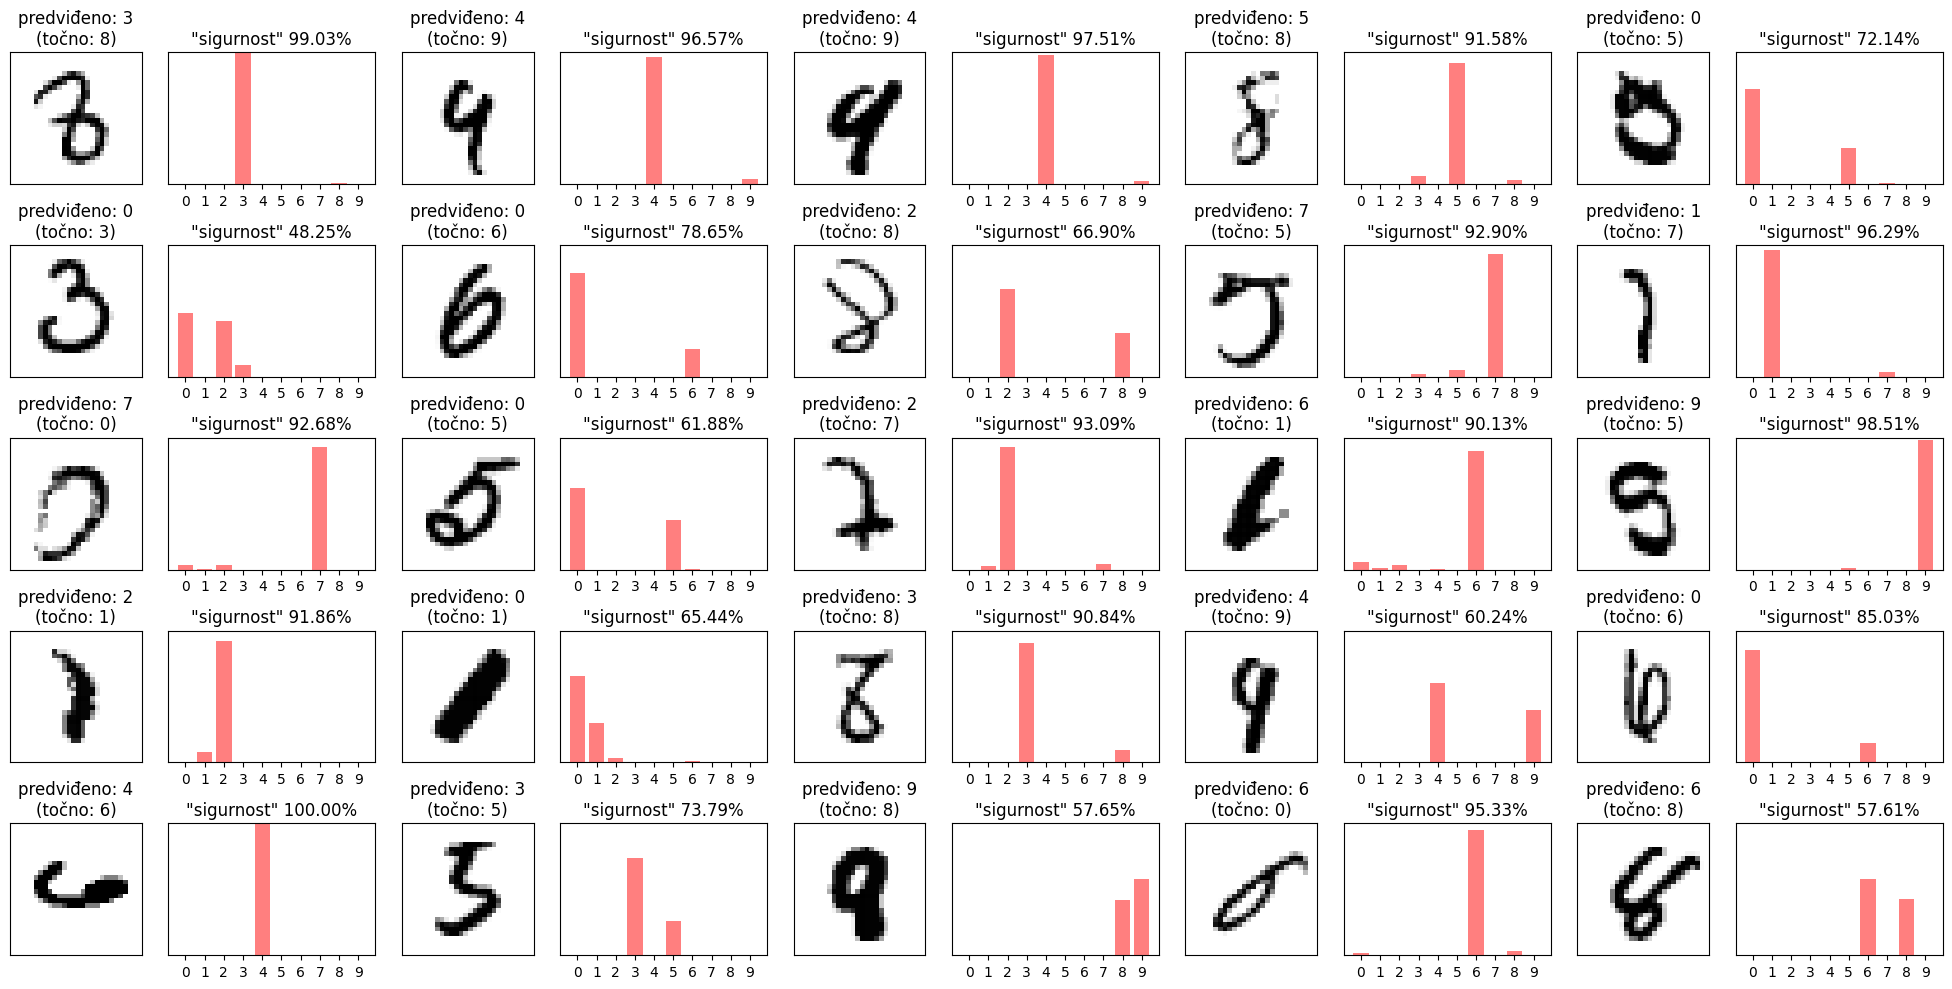

In [ ]:
fig = plt.figure(figsize = (20,10))
xs = np.arange(10)
cnt = 0

for i, pred, tocno, pred_vjerojatnosti in random.sample(pogresni, 25):
  cnt += 1
  ax1 = fig.add_subplot(5, 10, cnt)
  plt.title("predviđeno: {}\n(točno: {})".format(pred, tocno))
  plt.imshow(X_test[i].reshape(28,28), cmap="binary")
  plt.xticks([]), plt.yticks([])

  cnt += 1
  ax2 = fig.add_subplot(5, 10, cnt)
  sigurnost = pred_vjerojatnosti[pred] * 100
  plt.title("\"sigurnost\" {:.2f}%".format(sigurnost))
  plt.bar(xs, pred_vjerojatnosti, color="red", alpha=0.5)
  plt.xticks(xs), plt.yticks([])
  plt.ylim([0,1])
  plt.tight_layout()

# Usporedimo rezultate konvolucijske i FC mreže

(koja ima približno jednak broj parametara)

In [ ]:
model_FC = tf.keras.models.Sequential()
model_FC.add(tf.keras.Input(shape=(28, 28)))
model_FC.add(tf.keras.layers.Flatten())
model_FC.add(tf.keras.layers.Dense(64, activation='relu'))
model_FC.add(tf.keras.layers.Dense(128, activation='relu'))
model_FC.add(tf.keras.layers.Dense(64, activation='relu'))
model_FC.add(tf.keras.layers.Dense(32, activation='relu'))
model_FC.add(tf.keras.layers.Dense(10, activation='softmax'))

model_FC.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [ ]:
model_FC.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,226 (270.41 KB)

 Trainable params: 69,226 (270.41 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
povijest_FC = model_FC.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.2)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7954 - loss: 0.6550 - val_accuracy: 0.9480 - val_loss: 0.1730
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9564 - loss: 0.1458 - val_accuracy: 0.9647 - val_loss: 0.1192
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9690 - loss: 0.0990 - val_accuracy: 0.9660 - val_loss: 0.1157
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9768 - loss: 0.0742 - val_accuracy: 0.9682 - val_loss: 0.1075
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9811 - loss: 0.0595 - val_accuracy: 0.9688 - val_loss: 0.1116
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9842 - loss: 0.0484 - val_accuracy: 0.9703 - val_loss: 0.1066
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9873 - loss: 0.0427 - val_accuracy: 0.9695 - val_loss: 0.1135
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9880 - loss: 0.0368 - val_accuracy: 0.

In [ ]:
_, test_acc = model_FC.evaluate(X_test, y_test, verbose=0)
print("Tocnost na skupu za testiranje: {:.2f}%".format(test_acc*100))

Tocnost na skupu za testiranje: 97.11%


In [ ]:
def plot_history(hist_baseline, br_epoha, hist_FC=None):

    fig = plt.figure(figsize = (17,5))
    metrics = ["loss", "accuracy"]

    for i in range(len(metrics)):
        metric = metrics[i]
        plt.subplot(1, 2, i+1)
        plt.title(metric.capitalize())
        plt.xlabel("epoha")
        plt.ylabel(metric)
        plt.plot(range(1, br_epoha + 1), hist_baseline.history[metric],
                 label="train CNN", color="tab:blue")
        plt.plot(range(1, br_epoha + 1), hist_baseline.history["val_" + metric],
                 label="val CNN", color="tab:orange")

        if hist_FC:
            plt.plot(range(1, br_epoha + 1), hist_FC.history[metric],
                 label="train FC", color="tab:blue", linestyle='--', alpha=0.5)
            plt.plot(range(1, br_epoha + 1), hist_FC.history["val_" + metric],
                 label="val FC", color="tab:orange", linestyle='--', alpha=0.5)
        plt.legend()

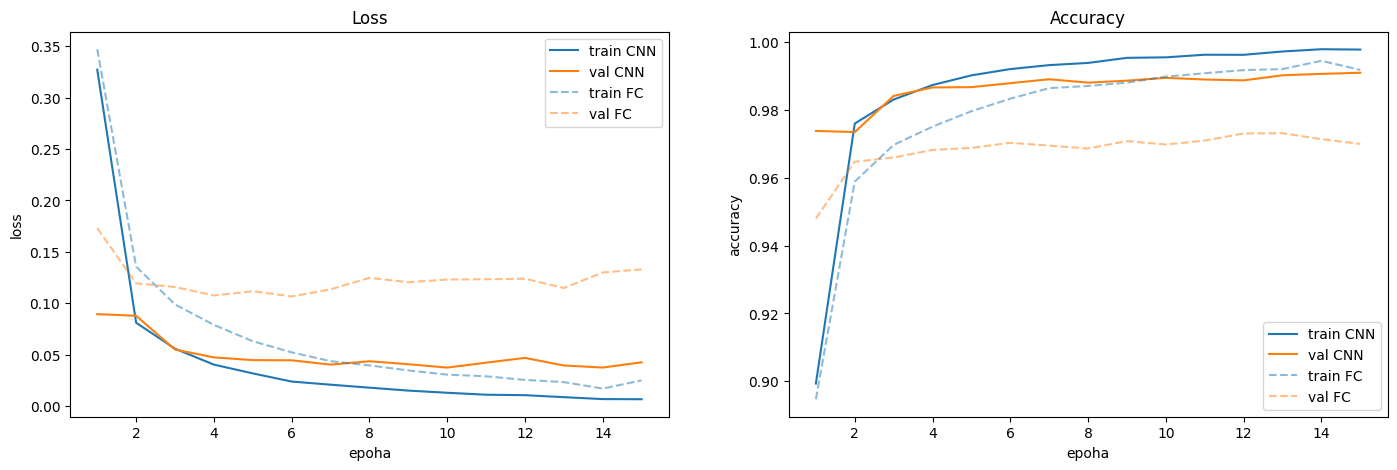

In [ ]:
plot_history(povijest, 15, povijest_FC)